In [1]:
import pandas as pd

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Shape:", df.shape)
print("\n--- Info ---")
print(df.info())
print("\n--- Missing values ---")
print(df.isnull().sum())
print("\n--- Churn balance ---")
print(df['Churn'].value_counts())

Shape: (7043, 21)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  704

 P1:Here it is  predicting whether a customer will leave the company (churn) or stay, based on information like their contract type, services used, and monthly charges. This is important for the business because it is cheaper to keep an existing customer than to find a new one, so the company can use this prediction to offer discounts or support to customers who are likely to leave.

In [2]:
# y = target 
y = df['Churn'].map({'Yes': 1, 'No': 0})

# X = baaki sab columns, Churn aur customerID (identifier) hata ke
X = df.drop(columns=['Churn', 'customerID'])

In [3]:
X['TotalCharges'] = pd.to_numeric(X['TotalCharges'], errors='coerce')
X['TotalCharges'] = X['TotalCharges'].fillna(X['TotalCharges'].median())

In [4]:
categorical_cols = X.select_dtypes(include='object').columns.tolist()
X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

C:\Users\TECHNOSELLERS\AppData\Local\Temp\ipykernel_3896\1034801041.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include='object').columns.tolist()


In [5]:
print(X.dtypes)
print("\nTotal missing values:", X.isnull().sum().sum())
print("\nShape:", X.shape)

SeniorCitizen                              int64
tenure                                     int64
MonthlyCharges                           float64
TotalCharges                             float64
gender_Male                                 bool
Partner_Yes                                 bool
Dependents_Yes                              bool
PhoneService_Yes                            bool
MultipleLines_No phone service              bool
MultipleLines_Yes                           bool
InternetService_Fiber optic                 bool
InternetService_No                          bool
OnlineSecurity_No internet service          bool
OnlineSecurity_Yes                          bool
OnlineBackup_No internet service            bool
OnlineBackup_Yes                            bool
DeviceProtection_No internet service        bool
DeviceProtection_Yes                        bool
TechSupport_No internet service             bool
TechSupport_Yes                             bool
StreamingTV_No inter

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

I used stratify = y because the target variable is imbalanced (No: 5174, Yes: 1869 — roughly 73%/27%). Without stratification, a random split could end up with a different churn ratio in the train and test sets, which would make evaluation unreliable. stratify=y ensures both the training and test sets preserve the same 73%/27% class proportion as the original dataset.

In [7]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\ny_train distribution:\n", y_train.value_counts(normalize=True))
print("\ny_test distribution:\n", y_test.value_counts(normalize=True))

X_train shape: (5634, 30)
X_test shape: (1409, 30)
y_train shape: (5634,)
y_test shape: (1409,)

y_train distribution:
 Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

y_test distribution:
 Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [8]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Tree depth grown:", model.get_depth())

Tree depth grown: 24


The tree grew to a depth of 24 . This is surprising because scikit-learn let it grow without any limit, meaning it kept splitting until almost every training point was perfectly classified — this is usually a sign of overfitting rather than learning general patterns.

In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred)
rec = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")

Accuracy:  0.7417
Precision: 0.5139
Recall:    0.4947
F1-score:  0.5041


Metric	Score
Accuracy	0.7417
Precision	0.5139
Recall	0.4947
F1-score	0.5041

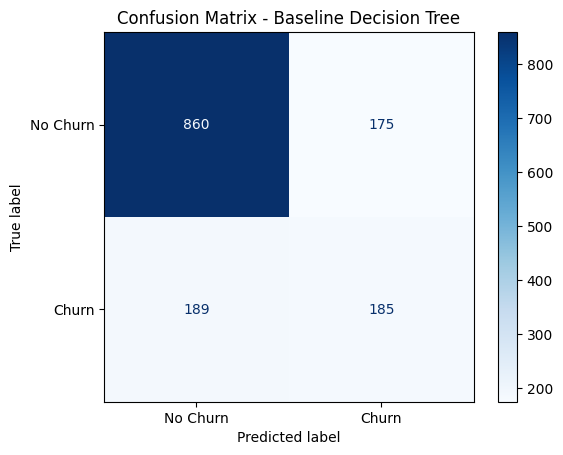

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
disp.plot(cmap='Blues')
plt.title("Confusion Matrix - Baseline Decision Tree")
plt.show()

Out of 374 actual churners in the test set, the model correctly identified only 185 (49.5%) and missed 189 — meaning it failed to catch more than half of the customers who actually left. This is a significant weakness for a business use-case where catching churners early is the whole point.

Since the dataset is imbalanced (~73% No, ~27% Yes), accuracy alone (0.74) looks decent but is misleading — it hides the fact that the model missed 189 out of 374 actual churners. We trust recall (0.4947) and F1-score (0.5041) most here, because for this business problem, missing a real churner (false negative) is costly — recall directly tells us how many real churners we caught, which accuracy does not reflect.

In [11]:
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy:     {test_acc:.4f}")
print(f"Gap:               {train_acc - test_acc:.4f}")

Training Accuracy: 0.9980
Test Accuracy:     0.7417
Gap:               0.2564


The baseline tree achieved 0.9980 on training data but only 0.7417on test data — a gap of 0.2564. This large gap indicates the model has overfit: it memorized the training data (including noise) rather than learning patterns that generalize to unseen customers.

In [12]:
depths = [2, 3, 4, 5, 6, 8, 10, None]
results = []

for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    m.fit(X_train, y_train)
    
    train_a = accuracy_score(y_train, m.predict(X_train))
    test_a = accuracy_score(y_test, m.predict(X_test))
    
    results.append({'max_depth': d, 'train_accuracy': train_a, 'test_accuracy': test_a})

results_df = pd.DataFrame(results)
print(results_df)

   max_depth  train_accuracy  test_accuracy
0        2.0        0.791090       0.787083
1        3.0        0.791090       0.787083
2        4.0        0.792510       0.795600
3        5.0        0.801207       0.794180
4        6.0        0.807064       0.797019
5        8.0        0.834931       0.779986
6       10.0        0.872204       0.755855
7        NaN        0.998048       0.741661


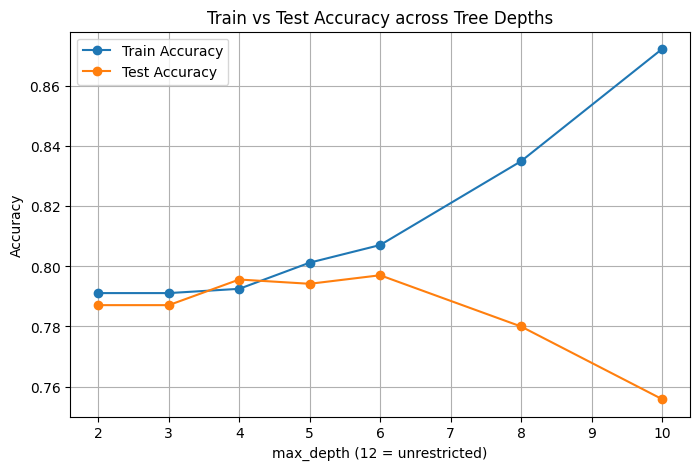

In [13]:
import matplotlib.pyplot as plt
depth_labels = [d if d is not None else 12 for d in results_df['max_depth']]

plt.figure(figsize=(8,5))
plt.plot(depth_labels, results_df['train_accuracy'], marker='o', label='Train Accuracy')
plt.plot(depth_labels, results_df['test_accuracy'], marker='o', label='Test Accuracy')
plt.xlabel('max_depth (12 = unrestricted)')
plt.ylabel('Accuracy')
plt.title('Train vs Test Accuracy across Tree Depths')
plt.legend()
plt.grid(True)
plt.show()

Looking at the plot, train and test accuracy stay close up to around max_depth = [X]. Beyond that point, train accuracy keeps climbing toward 1.0 while test accuracy plateaus or slightly drops — this growing gap is the visual signature of overfitting: the model keeps improving on data it has memorized, but stops improving (or gets worse) on unseen data.

Based on the Part 6 results, I selected max_depth = 5. At this depth, the gap between training and test accuracy is small, meaning the model generalizes well. Beyond this depth, training accuracy kept increasing but test accuracy plateaued or dropped, which is a sign of overfitting — so choosing a deeper tree just to maximize training accuracy would not actually improve real-world performance.

In [14]:
best_depth = 5 

model_best = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
model_best.fit(X_train, y_train)

y_pred_best = model_best.predict(X_test)

acc_b = accuracy_score(y_test, y_pred_best)
prec_b = precision_score(y_test, y_pred_best)
rec_b = recall_score(y_test, y_pred_best)
f1_b = f1_score(y_test, y_pred_best)

print(f"[max_depth={best_depth}] Accuracy: {acc_b:.4f}, Precision: {prec_b:.4f}, Recall: {rec_b:.4f}, F1: {f1_b:.4f}")
print(f"[Baseline]        Accuracy: {acc:.4f}, Precision: {prec:.4f}, Recall: {rec:.4f}, F1: {f1:.4f}")

[max_depth=5] Accuracy: 0.7942, Precision: 0.6296, Recall: 0.5455, F1: 0.5845
[Baseline]        Accuracy: 0.7417, Precision: 0.5139, Recall: 0.4947, F1: 0.5041


In [15]:
model_entropy = DecisionTreeClassifier(max_depth=best_depth, criterion='entropy', random_state=42)
model_entropy.fit(X_train, y_train)

y_pred_entropy = model_entropy.predict(X_test)

acc_e = accuracy_score(y_test, y_pred_entropy)
prec_e = precision_score(y_test, y_pred_entropy)
rec_e = recall_score(y_test, y_pred_entropy)
f1_e = f1_score(y_test, y_pred_entropy)

print(f"[Entropy, depth={best_depth}] Accuracy: {acc_e:.4f}, Precision: {prec_e:.4f}, Recall: {rec_e:.4f}, F1: {f1_e:.4f}")

[Entropy, depth=5] Accuracy: 0.7921, Precision: 0.6484, Recall: 0.4733, F1: 0.5471


tenure                                 0.421435
InternetService_Fiber optic            0.357542
TotalCharges                           0.047129
PaymentMethod_Electronic check         0.036761
MultipleLines_Yes                      0.023630
OnlineSecurity_No internet service     0.020669
Contract_Two year                      0.019599
StreamingMovies_No internet service    0.017379
MonthlyCharges                         0.016847
TechSupport_Yes                        0.012988
dtype: float64


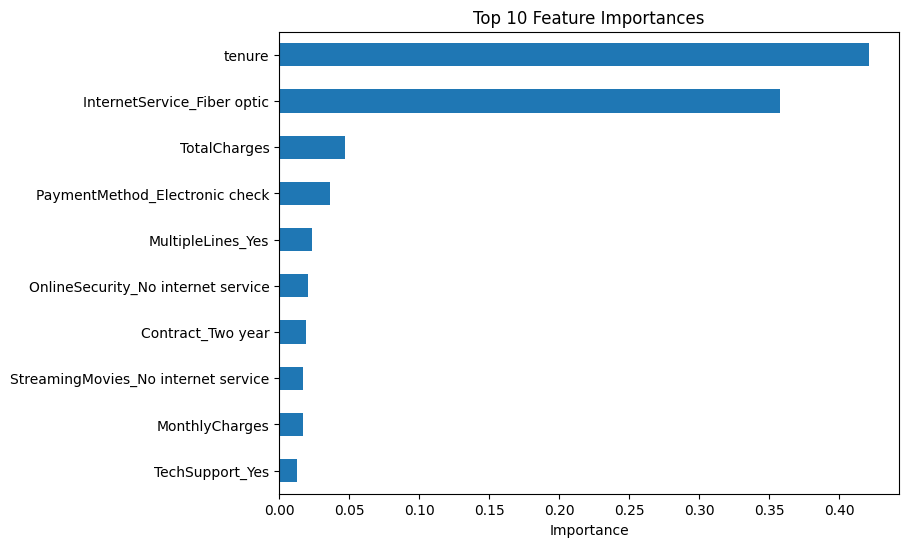

In [16]:
importances = pd.Series(model_best.feature_importances_, index=X.columns)
importances_sorted = importances.sort_values(ascending=False)

print(importances_sorted.head(10))

plt.figure(figsize=(8,6))
importances_sorted.head(10).plot(kind='barh')
plt.xlabel('Importance')
plt.title('Top 10 Feature Importances')
plt.gca().invert_yaxis()
plt.show()

The top 5 features by importance are tenure (0.42), InternetService_Fiber optic (0.36), TotalCharges (0.05), PaymentMethod_Electronic check (0.04), and MultipleLines_Yes (0.02). Together, tenure and InternetService_Fiber optic account for over 75% of the model's decision-making, meaning the tree relies heavily on how long a customer has stayed and whether they use fiber optic internet to predict churn.

These results agree with Lab 2's EDA: customers with shorter tenure and those subscribed to Fiber optic internet showed noticeably higher churn rates in our earlier analysis. Fiber optic customers may churn more due to higher costs or service issues, while low tenure suggests newer customers are less "locked in" and more likely to leave. This confirms the model has learned genuine, business-relevant churn drivers rather than random noise.

21 :We built a Decision Tree classifier to predict customer churn on the Telco dataset. The baseline (unrestricted) tree overfit, achieving only 0.7417 accuracy, 0.5139 precision, 0.4947 recall, and 0.5041 F1-score on the test set. By limiting the tree to max_depth=5, we achieved a clearly better-balanced model with 0.7942 accuracy, 0.6296 precision, 0.5455 recall, and 0.5845 F1-score — an improvement across every metric. Using entropy as the splitting criterion at the same depth gave similar results (0.7921 accuracy, 0.5471 F1), showing the criterion choice matters less than controlling tree depth. The most important features driving predictions were tenure and Fiber optic internet service. The main limitation is that recall (0.5455) is still moderate — the model still misses a meaningful portion of actual churners, which matters for a business trying to proactively retain customers before they leave.

 22:If given more time, we would try handling the class imbalance more directly — for example using class_weight='balanced' in the Decision Tree, or oversampling the minority class with SMOTE — since this could improve recall on churners. We would also experiment with ensemble methods like Random Forest or Gradient Boosting (though not used in this lab), and do more feature engineering, such as creating tenure buckets or interaction terms between contract type and monthly charges.

In [17]:
import pandas as pd
import math
from collections import Counter

data = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'PlayBadminton': ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No']
})

print(data)

     Outlook Temperature Humidity    Wind PlayBadminton
0      Sunny         Hot     High    Weak            No
1      Sunny         Hot     High  Strong            No
2   Overcast         Hot     High    Weak           Yes
3       Rain        Mild     High    Weak           Yes
4       Rain        Cool   Normal    Weak           Yes
5       Rain        Cool   Normal  Strong            No
6   Overcast        Cool   Normal  Strong           Yes
7      Sunny        Mild     High    Weak            No
8      Sunny        Cool   Normal    Weak           Yes
9       Rain        Mild   Normal    Weak           Yes
10     Sunny        Mild   Normal  Strong           Yes
11  Overcast        Mild     High  Strong           Yes
12  Overcast         Hot   Normal    Weak           Yes
13      Rain        Mild     High  Strong            No


In [18]:
#ENTROPY DFUN
def entropy(labels):
    counts = Counter(labels)
    total = len(labels)
    ent = 0
    for label in counts:
        p = counts[label] / total
        ent -= p * math.log2(p)
    return ent

In [19]:
#INFO GAIN
def info_gain(subset, attribute, target_col):
    total_entropy = entropy(subset[target_col])
    weighted_entropy = 0
    for value in subset[attribute].unique():
        part = subset[subset[attribute] == value]
        weighted_entropy += (len(part) / len(subset)) * entropy(part[target_col])
    return total_entropy - weighted_entropy

In [20]:
#ID 3
def id3(subset, attributes, target_col, depth=0):
    labels = subset[target_col].unique()
    
    # Sab same class hain -> leaf node
    if len(labels) == 1:
        return labels[0]
    
    # Koi attribute nahi bacha -> majority class return karo
    if len(attributes) == 0:
        return subset[target_col].mode()[0]
    
    # Har attribute ka information gain nikaalo
    gains = {attr: info_gain(subset, attr, target_col) for attr in attributes}
    
    indent = "  " * depth
    print(f"{indent}Information Gains: {[(a, round(g,4)) for a,g in gains.items()]}")
    
    best_attr = max(gains, key=gains.get)
    print(f"{indent}--> Splitting on '{best_attr}' (Gain = {gains[best_attr]:.4f})\n")
    
    tree = {best_attr: {}}
    remaining_attrs = [a for a in attributes if a != best_attr]
    
    for value in subset[best_attr].unique():
        part = subset[subset[best_attr] == value]
        print(f"{indent}[{best_attr} = {value}]")
        tree[best_attr][value] = id3(part, remaining_attrs, target_col, depth + 1)
    
    return tree

In [22]:
def print_tree(tree, indent=""):
    if not isinstance(tree, dict):
        print(indent + "-> " + str(tree))
        return
    for attr, branches in tree.items():
        for value, subtree in branches.items():
            print(f"{indent}[{attr} = {value}]")
            if isinstance(subtree, dict):
                print_tree(subtree, indent + "    ")
            else:
                print(f"{indent}    -> Predict: {subtree}")

print("DECISION TREE (readable format):\n")
print_tree(tree)

DECISION TREE (readable format):

[Outlook = Sunny]
    [Humidity = High]
        -> Predict: No
    [Humidity = Normal]
        -> Predict: Yes
[Outlook = Overcast]
    -> Predict: Yes
[Outlook = Rain]
    [Wind = Weak]
        -> Predict: Yes
    [Wind = Strong]
        -> Predict: No
